# Ajuste Direto contracts

Contracts whose `tipo_procedimento` is an Ajuste Direto variant. Four verbatim values exist:

- `Ajuste Direto Regime Geral` — 178 523
- `Ajuste direto simplificado ao abrigo da Lei n.º 30/2021, de 21.05` — 1 631
- `Ajuste Direto Regime Geral ao abrigo do artigo 7º da Lei n.º 30/2021, de 21.05` — 18
- `Ajuste direto simplificado` — 2

**Rule:** `tipo_procedimento.str.to_lowercase().str.starts_with("ajuste direto")` (casing is inconsistent,
so no exact-equality list). Reference: **180 174 rows (44.0 % of 409 344)** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
    split_packed,
)

from base_gov.stats import value_impact, value_per_day

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_raw = pl.read_parquet(DATA / "contracts.parquet")
print(f"rows={contracts_raw.height:,}  cols={contracts_raw.width}")


contracts_all = (
    entity_key(
        contracts_raw.with_columns(split_packed("adjudicante", prefix="adjudicante")),
        prefix="adjudicante",
    )
    .select(
        pl.col("idcontrato"),
        pl.col("adjudicante"),
        pl.col("adjudicante_nipc"),
        pl.col("adjudicante_name"),
        pl.col("adjudicante_key"),
        pl.col("adjudicante_key_source"),
        pl.col("adjudicatarios"),
        pl.col("objectoContrato").alias("objecto_contrato"),
        pl.col("precoContratual").alias("preco_contratual"),
        pl.col("prazoExecucao").alias("prazo_execucao"),
        pl.col("dataCelebracaoContrato").alias("data_celebracao"),
        pl.col("CPV").alias("cpv"),
        pl.col("NUTs").alias("nuts"),
        pl.col("Ano").alias("ano"),
        pl.col("tipoContrato").alias("tipo_contrato"),
        pl.col("tipoprocedimento").alias("tipo_procedimento"),
        pl.col("fundamentAjusteDireto").alias("fundament_ajuste_direto"),
)
)
contracts_all = contracts_all.with_columns(value_per_day())
# Disregard contracts priced below MIN_VALUE (€); contracts_all keeps them for before/after comparisons.
MIN_VALUE = 10
contracts = contracts_all.filter(pl.col("preco_contratual") >= MIN_VALUE)
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with preco_contratual < €{MIN_VALUE} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=409,344  cols=39
disregarded 1,490 contracts with preco_contratual < €10 (0.36%); kept 407,854
valor_por_dia defined for 98.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 407852 │
│ name                   ┆ 2      │
└────────────────────────┴────────┘


In [3]:
AD_EXPR = pl.col("tipo_procedimento").str.to_lowercase().str.starts_with("ajuste direto")
contracts["tipo_procedimento"].value_counts(sort=True)


tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",178076
"""Consulta Prévia""",67709
"""Concurso público""",63029
"""Ao abrigo de acordo-quadro (ar…",55195
"""Contratação excluída II""",27226
"""Ao abrigo de acordo-quadro (ar…",10459
"""Setores especiais – isenção pa…",2244
"""Ajuste direto simplificado ao …",1530
"""Consulta Prévia Simplificada""",1218


In [4]:
ajuste = contracts.filter(AD_EXPR)
print(f"Ajuste Direto rows: {ajuste.height:,}  share by count: {ajuste.height / contracts.height:.1%}  "
      f"share by value: {ajuste['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = ajuste["tipo_procedimento"].value_counts(sort=True)
assert variants["count"].sum() == ajuste.height and ajuste.height < contracts.height
variants


Ajuste Direto rows: 179,626  share by count: 44.0%  share by value: 13.8%


tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",178076
"""Ajuste direto simplificado ao …",1530
"""Ajuste Direto Regime Geral ao …",18
"""Ajuste direto simplificado""",2


In [5]:
# Effect of disregarding contracts priced below €10 on Ajuste Direto.
before = contracts_all.filter(AD_EXPR)
display(value_impact(before, ajuste))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",180174.0,179626.0,-548.0,-0.3
"""mean_value""",28960.429478,29049.009992,88.580514,0.31
"""median_value""",8730.0,8763.045,33.045,0.38
"""total_value""",5.2179e9,5.2180e9,41048.009999,0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 3,203 of 179,626


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
3.0,20.0,56.0,275.0,365.0,10.85,29.63,101.76,446.03,1750.0


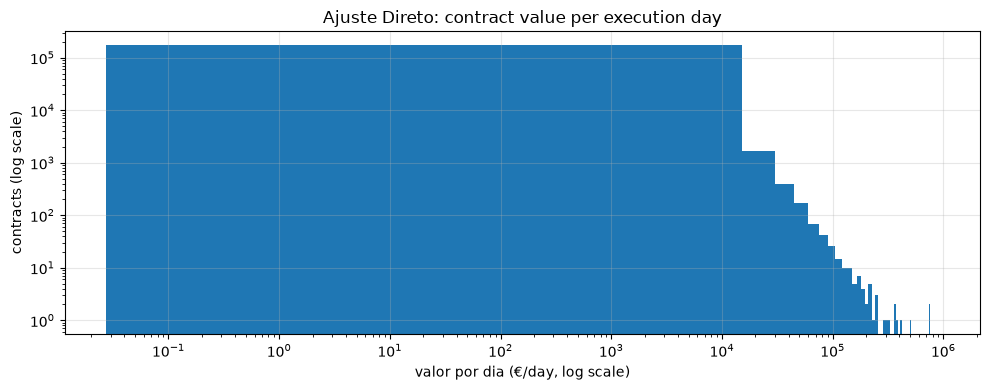

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = ajuste
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Ajuste Direto: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    ajuste.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",80242,5000.0,336.05,9.12382486e8
"""91-365 d""",61791,11462.5,44.68,2.8437e9
"""31-90 d""",21191,12000.0,205.28,6.76812666e8
"""366-3650 d""",13199,17729.4,18.74,7.50571322e8


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(ajuste, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))


shape: (2, 2)
┌───────────────────────┬────────┐
│ adjudicatarios_status ┆ count  │
│ ---                   ┆ ---    │
│ str                   ┆ u32    │
╞═══════════════════════╪════════╡
│ YES                   ┆ 157203 │
│ NO_NIF                ┆ 24163  │
└───────────────────────┴────────┘
shape: (2, 2)
┌───────────────────────────┬────────┐
│ adjudicatarios_key_source ┆ count  │
│ ---                       ┆ ---    │
│ str                       ┆ u32    │
╞═══════════════════════════╪════════╡
│ nipc                      ┆ 157203 │
│ name                      ┆ 24163  │
└───────────────────────────┴────────┘


In [9]:
by_adjudicante = (
    ajuste.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(ajuste, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Ajuste Direto count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Ajuste Direto value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))


Top 20 adjudicantes by Ajuste Direto count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""506362299""",21311,1.6280e8,"""Instituto Português de Oncolog…"
"""508142156""",7693,9.7184e7,"""Unidade Local de Saúde de Gaia…"
"""506361470""",5239,6.5837725e7,"""Unidade Local de Saúde de Alma…"
"""510103448""",4332,2.4378e8,"""Unidade Local de Saúde de Coim…"
"""508094461""",3984,2.1875e7,"""Unidade Local de Saúde do Alto…"
"""510745997""",3311,9.2063e7,"""Unidade Local de Saúde do Alga…"
"""509822940""",2324,5.6421e7,"""Unidade Local de Saúde de Vise…"
"""500122237""",2324,7.9951e6,"""Fundação INATEL"""
"""508481287""",2166,2.1804e8,"""Unidade Local de Saúde de Sant…"



Top 20 adjudicantes by Ajuste Direto value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""510103448""",4332,2.4378e8,"""Unidade Local de Saúde de Coim…"
"""508481287""",2166,2.1804e8,"""Unidade Local de Saúde de Sant…"
"""503933813""",478,1.9518e8,"""Infraestruturas de Portugal, S…"
"""506362299""",21311,1.6280e8,"""Instituto Português de Oncolog…"
"""508080142""",1405,1.4710e8,"""Unidade Local de Saúde de São …"
"""515545180""",1510,1.2977e8,"""Unidade Local Saúde de Braga, …"
"""509821197""",1586,1.1943e8,"""Unidade Local de Saúde de São …"
"""508142156""",7693,9.7184e7,"""Unidade Local de Saúde de Gaia…"
"""517392259""",558,9.6221e7,"""Unidade Local de Saúde de Sant…"


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(ajuste.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")


Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""501506543""",2054,2.8356e7,"""nipc""","""B BRAUN MEDICAL UNIPESSOAL, LD…"
"""504223933""",1835,5.9682e7,"""nipc""","""MEDTRONIC PORTUGAL, LDA."""
"""500153370""",1203,3.3664e7,"""nipc""","""JOHNSON &amp; JOHNSON LDA."""
"""503531588""",940,1.7615e7,"""nipc""","""Lusopalex - Produtos de Saude …"
"""503934640""",734,6.8714e7,"""nipc""","""ALLOGA LOGIFARMA, SA"""
"""980474710""",716,1.6182e7,"""nipc""","""Olympus Iberia, S.A.U, Sucursa…"
"""504594214""",704,1.2850e7,"""nipc""","""Stryker Portugal Produtos Médi…"
"""504988964""",660,1.3199e7,"""nipc""","""Boston Scientific Portugal, Di…"
"""503347345""",652,8.9193e6,"""nipc""","""BAXTER MEDICO – FARMACEUTICA"""



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""513481613""",80,8.9738e7,"""nipc""","""VERTEX PHARMACEUTICALS (PORTUG…"
"""500134960""",606,7.3184e7,"""nipc""","""SANOFI- PRODUTOS FARMACÊUTICOS…"
"""500189412""",597,7.1124e7,"""nipc""","""JANSSEN CILAG FARMACEUTICA, LD…"
"""503934640""",734,6.8714e7,"""nipc""","""ALLOGA LOGIFARMA, SA"""
"""512033838""",1,6.4529435e7,"""nipc""","""Bencom- Armazenamento e Comérc…"
"""504223933""",1835,5.9682e7,"""nipc""","""MEDTRONIC PORTUGAL, LDA."""
"""500233810""",503,4.4463e7,"""nipc""","""ROCHE FARMACÊUTICA QUIMICA, LD…"
"""501400699""",7,4.2882155e7,"""nipc""","""EID - Empresa de Investigação …"
"""500697370""",199,4.2565e7,"""nipc""",""" Petrogal, S.A."""


awardee entries keyed by name fallback: 24,163 of 181,366 (13.3%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = ajuste.group_by("adjudicante_key", "adjudicante_name").len()
new = ajuste.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    ajuste.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)


adjudicante rows: 5,654 (key, name spelling) -> 4,280 keys
adjudicatario rows: 61,182 (key, name) -> 45,035 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""501413197""",47,584
"""501442600""",41,833
"""600012662""",13,1415
"""501559094""",11,794
"""508184509""",10,88


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 179626.0      │
│ null_count ┆ 0.0           │
│ mean       ┆ 29049.009992  │
│ std        ┆ 263825.200931 │
│ min        ┆ 10.0          │
│ 25%        ┆ 2610.0        │
│ 50%        ┆ 8763.05       │
│ 75%        ┆ 18000.0       │
│ max        ┆ 6.4529435e7   │
└────────────┴───────────────┘


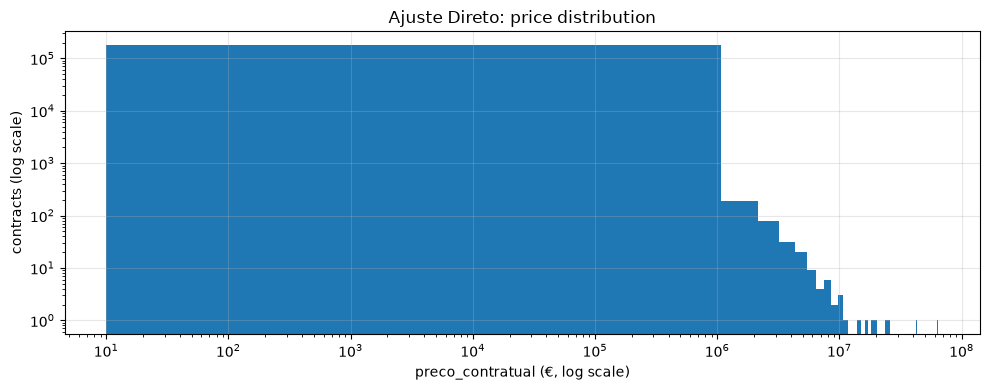

contracts above €5,000: 120,623
contracts above €20,000: 29,555
contracts above €75,000: 9,788


In [12]:
prices = ajuste["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Ajuste Direto: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")


In [13]:
print(f"fundament_ajuste_direto null rate: {ajuste['fundament_ajuste_direto'].null_count() / ajuste.height:.1%}")
ajuste["fundament_ajuste_direto"].value_counts(sort=True).head(15)


fundament_ajuste_direto null rate: 86.8%


fundament_ajuste_direto,count
str,u32
null,155975
"""ausência de recursos próprios""",23639
"""outros""",12


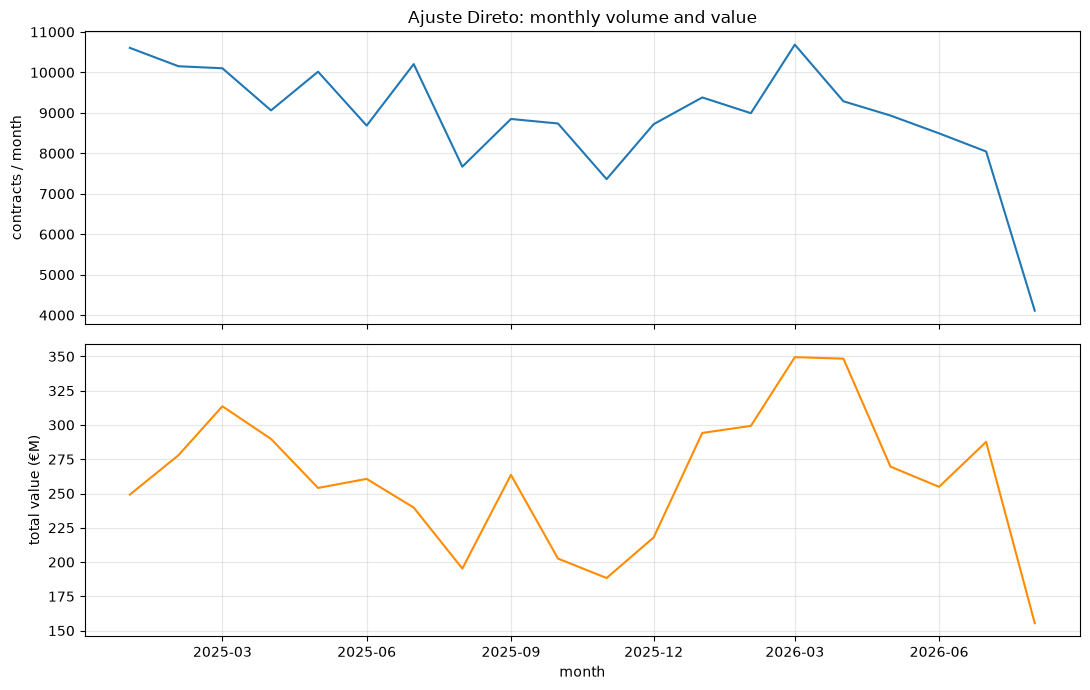

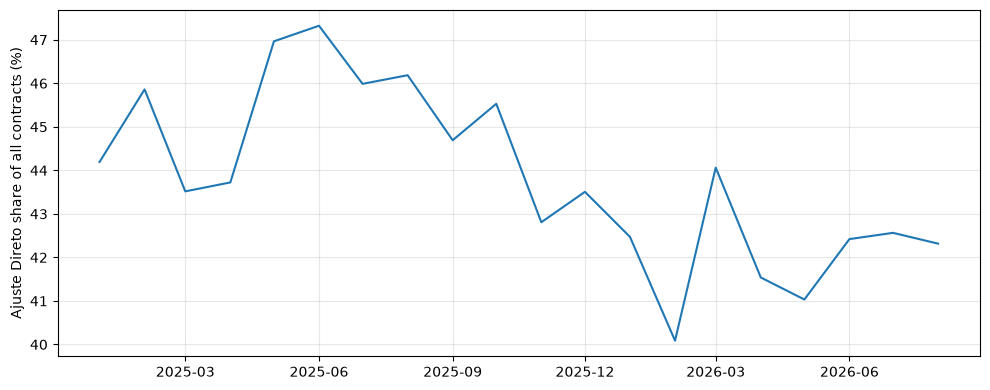

In [14]:
ad_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        AD_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(AD_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = ad_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Ajuste Direto: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(ad_monthly["month"], ad_monthly["share"] * 100)
ax.set_ylabel("Ajuste Direto share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
ajuste.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)


idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
11758845,"""EDA - Electricidade dos Açores…",6.4529435e7,"""Ajuste Direto Regime Geral""",2025-09-30,"""Fornecimento de Fuelóleo às Ce…"
12796026,"""MARINHA - Direção de Abastecim…",4.23e7,"""Ajuste Direto Regime Geral""",2026-01-20,"""3025006631 Fornecimento de Sis…"
13444677,"""Infraestruturas de Portugal""",2.5000e7,"""Ajuste Direto Regime Geral""",2026-02-13,"""Empreitada L. MINHO - CONTUMIL…"
11547715,"""Fundação para a Ciência e a Te…",2.4007285e7,"""Ajuste Direto Regime Geral""",2025-06-27,"""RI/00442/2024 - Conteúdos b-on…"
15278361,"""APDL - Administração dos Porto…",1.9977e7,"""Ajuste Direto Regime Geral""",2026-07-09,"""Empreitada de Restabelecimento…"
11560178,"""Metro do Porto, S. A.""",1.8874e7,"""Ajuste Direto Regime Geral""",2025-06-30,"""CONTINUIDADE DA PRESTAÇÃO DO S…"
14613724,"""Unidade Local de Saúde do Médi…",1.6908903e7,"""Ajuste Direto Regime Geral""",2026-04-15,"""Serviço de transporte não urge…"
11969253,"""Estado Maior da Força Aérea""",1.5e7,"""Ajuste Direto Regime Geral""",2025-11-20,"""AQUISIÇÃO DE DOIS SISTEMAS MOD…"
15257464,"""Infraestruturas de Portugal, S…",1.14898e7,"""Ajuste Direto Regime Geral""",2026-07-03,"""EMPREITADA - L. OESTE - MELEÇA…"


## Commentary and limitations

- `Ano` covers 2025–2026 only; edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- The €5 000 / €20 000 / €75 000 lines are informal reference points, not legal thresholds.
- Very large values may be outliers or data-entry errors.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`, blocked by first token/length) and may over- or under-merge; see `key_source`.
- Dirty NIPCs (wrong length, stray characters) are kept as separate keys, not merged by name.

- Contracts priced below €10 (`MIN_VALUE`) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.
